# Non-neural energy baseline

## Handcrafted event features vs muon energy at the detector entrance

Этот ноутбук показывает качество **не-нейросетевых** моделей реконструкции энергии
мюона. Он читает только сохранённые артефакты: матрицу event-level признаков,
обученные модели и предсказания. Ни обучения, ни чтения h5, ни выбора чекпоинта
здесь нет.

Данные: `mu_energy_dataset_h8s3_thr0.8_train1M_partsplit` — flat-отбор только по
train-партам. Внутри датасета используется тот же event-level split, что у
нейросети: 900k train / 80k val-select / 20k calibration. Новые test-парты в
этот датасет не входят и будут оцениваться отдельно.

Заряд во всех признаках обрезан на `Q = 100 p.e.` — так же, как на входе
нейросети. Это важно для честного сравнения архитектур.

Сравнение с нейросетью — **последний** блок ноутбука. Он не знает о конкретном
чекпоинте: пути к предсказаниям задаются в одной ячейке, и при смене чекпоинта
меняется только эта ячейка.

> **Важно: это не финальный part-level test.**
>
> Все графики качества ниже построены на `calibration` (20k событий) внутри
> **train-партов**. `train` — in-sample, `val-select` использовался для выбора
> гиперпараметров, `calibration` отложен от выбора модели, но относится к тем же
> train-партам. Новые test-парты в этом датасете отсутствуют; их оценка будет
> отдельным этапом.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import duckdb
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 9})

ROOT = Path.cwd()
if not (ROOT / "trained_models").exists():
    ROOT = (ROOT / "../../..").resolve()

RUN_NAME = "261026_1725_non_neural_energy_baseline_partsplit_s42"
RUN = ROOT / "trained_models/track_energy_reconstruction" / RUN_NAME
PRED_DB = RUN / "predictions.duckdb"
print("run:", RUN)
print("exists:", RUN.exists(), "| predictions:", PRED_DB.exists())

run: /home/albert/Baikal2025/trained_models/track_energy_reconstruction/261026_1725_non_neural_energy_baseline_partsplit_s42
exists: True | predictions: True


In [2]:
with open(RUN / "metrics.json") as f:
    metrics = json.load(f)
with open(RUN / "feature_names.json") as f:
    feature_info = json.load(f)

model_order = ["loglinear", "ridge", "hgb"]
model_labels = {
    "loglinear": "log-linear (3 features)",
    "ridge": "Ridge (50 features)",
    "hgb": "HGB (50 features)",
    "hgb_counts_charge": "HGB counts+charge",
    "hgb_counts_charge_geometry": "HGB +geometry",
}
colors = {
    "loglinear": "#0072B2",
    "ridge": "#E69F00",
    "hgb": "#009E73",
    "hgb_counts_charge": "#999999",
    "hgb_counts_charge_geometry": "#CC79A7",
}
main_models = model_order

print("split sizes:", metrics["split_sizes"])
print("features:", len(feature_info["feature_names"]), "| amp_clip:", feature_info["amp_clip"])
print("selected:", json.dumps(metrics["model_selection"], indent=2))

split sizes: {'train': 900000, 'val_select': 80000, 'cal': 20000}
features: 50 | amp_clip: 100.0
selected: {
  "loglinear": {
    "kind": "loglinear"
  },
  "ridge": {
    "kind": "ridge",
    "alpha": 0.1,
    "val_mae": 0.6214000301319945
  },
  "hgb": {
    "params": {
      "max_iter": 500,
      "learning_rate": 0.05,
      "max_leaf_nodes": 63,
      "l2_regularization": 1.0,
      "loss": "squared_error"
    },
    "val_mae": 0.5122238157650525
  },
  "hgb_counts_charge": {
    "params": {
      "max_iter": 500,
      "learning_rate": 0.05,
      "max_leaf_nodes": 63,
      "l2_regularization": 1.0,
      "loss": "squared_error"
    }
  },
  "hgb_counts_charge_geometry": {
    "params": {
      "max_iter": 500,
      "learning_rate": 0.05,
      "max_leaf_nodes": 63,
      "l2_regularization": 1.0,
      "loss": "squared_error"
    }
  }
}


## 1. Глобальное качество (calibration; train — in-sample)

MAE и RMSE — в dex; `bias = mean(y_true - y_pred)`, положительный bias означает
систематическое занижение энергии. `within ×2` — доля событий с ошибкой не более
`log10(2)`. `w_*` — те же метрики с flat-весами; они полезны для хвостов, но
хуже читаются как «средняя точность».

In [3]:
rows = []
for split in ["train", "val_select", "cal"]:
    for model in model_order:
        m = metrics["global"][split][model]
        rows.append({
            "split": split,
            "model": model,
            "n": int(m["n"]),
            "MAE": m["mae"],
            "RMSE": m["rmse"],
            "bias": m["bias"],
            "median_AE": m["median_ae"],
            "within_x2": m["within_factor_2"],
            "within_x5": m["within_factor_5"],
            "w_MAE": m.get("w_mae", np.nan),
        })
global_df = pd.DataFrame(rows)
show_df = global_df.copy()
show_df["split"] = show_df.split.map({
    "train": "train (in-sample)",
    "val_select": "val-select (selection)",
    "cal": "calibration (event-level holdout)",
})
display(show_df.style.format({
    "MAE": "{:.4f}", "RMSE": "{:.4f}", "bias": "{:+.4f}",
    "median_AE": "{:.4f}", "within_x2": "{:.3f}",
    "within_x5": "{:.3f}", "w_MAE": "{:.4f}",
}))

,split,model,n,MAE,RMSE,bias,median_AE,within_x2,within_x5,w_MAE
0,train (in-sample),loglinear,900000,0.7581,0.9622,+0.1533,0.6216,0.248,0.553,0.9033
1,train (in-sample),ridge,900000,0.6183,0.8082,+0.1167,0.4890,0.327,0.655,0.7028
2,train (in-sample),hgb,900000,0.5010,0.6664,+0.0590,0.3804,0.408,0.752,0.4934
3,val-select (selection),loglinear,80000,0.7603,0.9658,+0.1483,0.6230,0.247,0.552,0.9158
4,val-select (selection),ridge,80000,0.6214,0.8121,+0.1120,0.4929,0.324,0.651,0.7146
5,val-select (selection),hgb,80000,0.5122,0.6857,+0.0542,0.3837,0.405,0.745,0.5405
6,calibration (event-level holdout),loglinear,20000,0.7611,0.9679,+0.1498,0.6234,0.249,0.550,0.9110
7,calibration (event-level holdout),ridge,20000,0.6172,0.8094,+0.1212,0.4860,0.329,0.657,0.7028
8,calibration (event-level holdout),hgb,20000,0.5136,0.6889,+0.0614,0.3872,0.404,0.744,0.5318


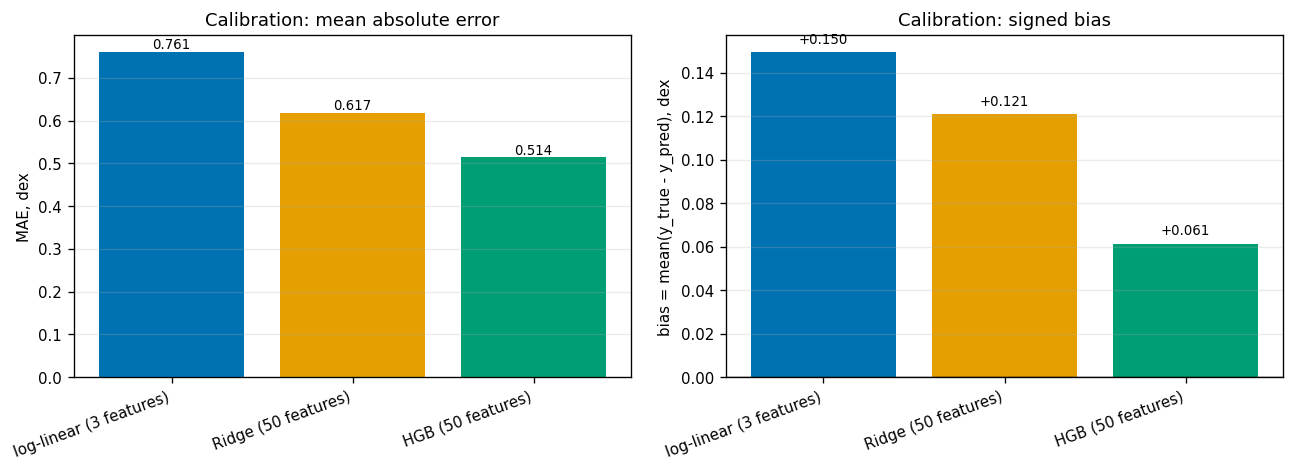

In [4]:
cal = global_df[global_df.split == "cal"].set_index("model").loc[model_order]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), sharex=True)
x = np.arange(len(cal))
axes[0].bar(x, cal["MAE"], color=[colors[m] for m in cal.index])
axes[0].set_xticks(x, [model_labels[m] for m in cal.index], rotation=20, ha="right")
axes[0].set_ylabel("MAE, dex")
axes[0].set_title("Calibration: mean absolute error")
for i, v in enumerate(cal["MAE"]):
    axes[0].text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=8)
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(x, cal["bias"], color=[colors[m] for m in cal.index])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xticks(x, [model_labels[m] for m in cal.index], rotation=20, ha="right")
axes[1].set_ylabel("bias = mean(y_true - y_pred), dex")
axes[1].set_title("Calibration: signed bias")
for i, v in enumerate(cal["bias"]):
    axes[1].text(i, v + (0.004 if v >= 0 else -0.012), f"{v:+.3f}", ha="center", fontsize=8)
axes[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 2. Качество по истинной энергии (calibration, внутри train-партов)

Глобальное MAE скрывает главное: низкие энергии реконструируются хуже, высокие —
лучше. Ниже показаны MAE, bias и `within ×2` в бинах `log10(E/GeV)`. Бины с
`n < 20` не рисуются (они остаются в parquet-таблицах), чтобы не выдавать
несколько событий за измерение.

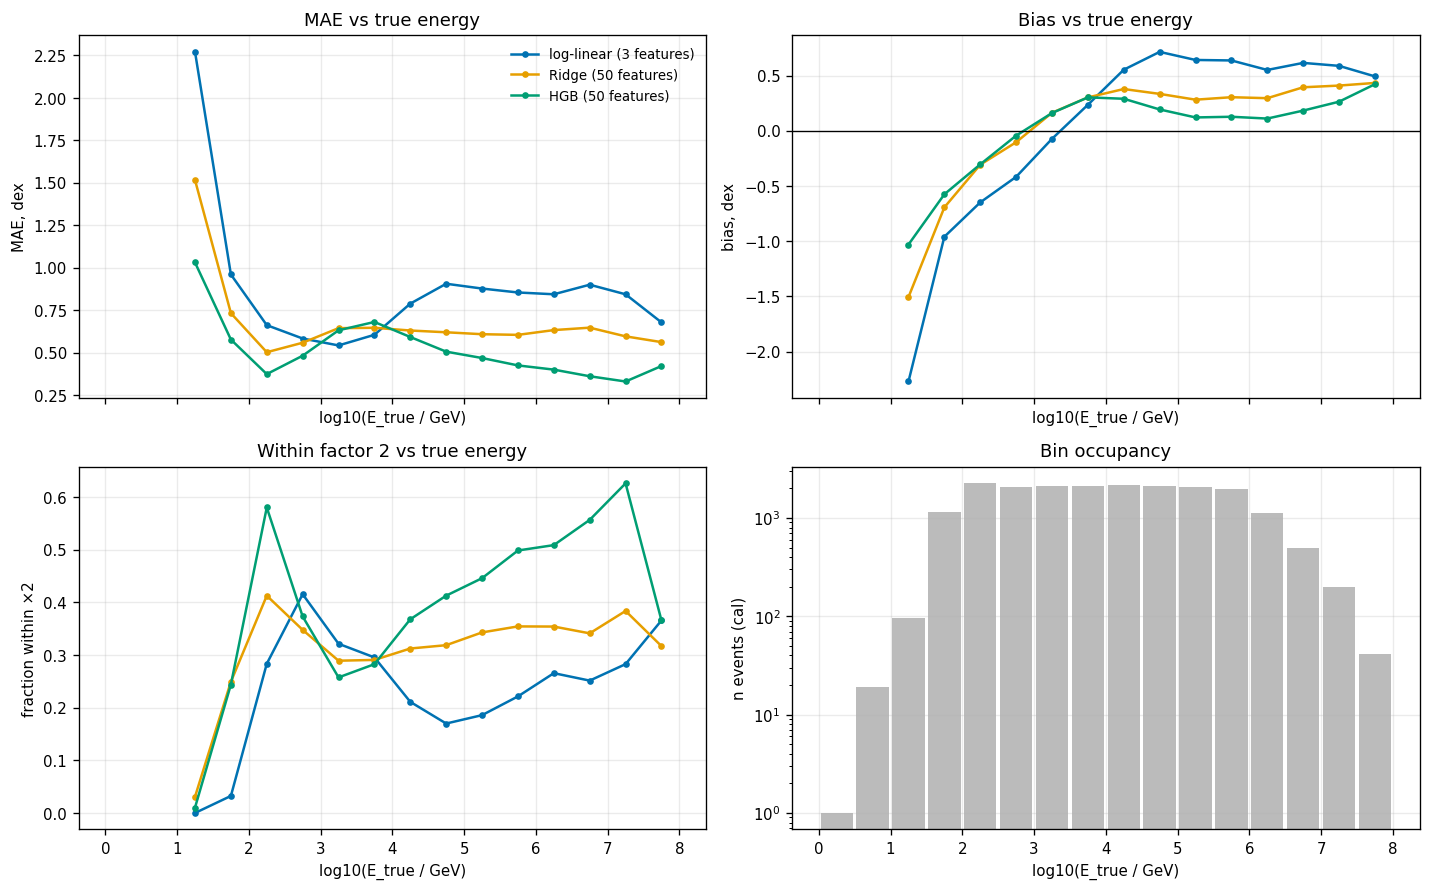

In [5]:
bins_df = pd.read_parquet(RUN / "metrics_by_true_energy.parquet")
bins_df = bins_df[(bins_df.split == "cal") & (bins_df.model.isin(main_models))].copy()
bins_df["center"] = 0.5 * (bins_df.bin_lo + bins_df.bin_hi)
plot_df = bins_df[bins_df.n >= 20]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for model in main_models:
    d = plot_df[plot_df.model == model].sort_values("center")
    axes[0, 0].plot(d.center, d.mae, marker="o", ms=3, lw=1.5,
                    color=colors[model], label=model_labels[model])
    axes[0, 1].plot(d.center, d.bias, marker="o", ms=3, lw=1.5,
                    color=colors[model])
    axes[1, 0].plot(d.center, d.within_factor_2, marker="o", ms=3, lw=1.5,
                    color=colors[model])
axes[0, 0].set_ylabel("MAE, dex")
axes[0, 0].set_title("MAE vs true energy")
axes[0, 1].axhline(0, color="black", lw=0.8)
axes[0, 1].set_ylabel("bias, dex")
axes[0, 1].set_title("Bias vs true energy")
axes[1, 0].set_ylabel("fraction within ×2")
axes[1, 0].set_title("Within factor 2 vs true energy")
axes[1, 0].set_xlabel("log10(E_true / GeV)")
axes[1, 1].set_xlabel("log10(E_true / GeV)")
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.set_xlabel("log10(E_true / GeV)")
# counts panel: same bins, once
counts = bins_df[bins_df.model == "hgb"].sort_values("center")
axes[1, 1].bar(counts.center, counts.n, width=0.45, color="#BBBBBB")
axes[1, 1].set_yscale("log")
axes[1, 1].set_ylabel("n events (cal)")
axes[1, 1].set_title("Bin occupancy")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 3. Предсказание против истины

Плотность событий в плоскости `(E_true, E_pred)` на калибровочной выборке.
Пунктир — идеальная реконструкция. Цвет — число событий, логарифмическая шкала.
Панели имеют одинаковые оси; отдельная цветовая шкала не нужна.

/tmp/ipykernel_4013074/1074660911.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


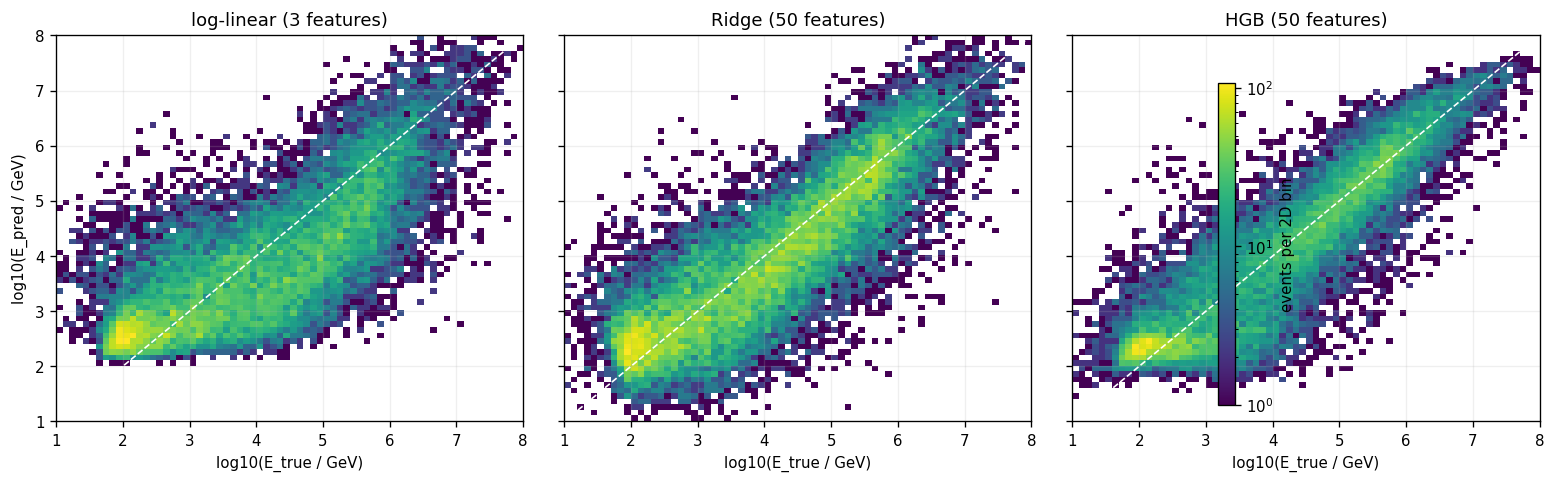

In [6]:
con = duckdb.connect(str(PRED_DB), read_only=True)
pred = con.execute("""
    SELECT event_fk, split, true_log10e, pred_log10e, model,
           n_hits, particle_type, flat_weight, part_key
    FROM predictions
""").df()
con.close()

cal_pred = pred[pred.split == "cal"].copy()
bins_2d = np.linspace(1.0, 8.0, 71)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.1), sharex=True, sharey=True)
for ax, model in zip(axes, main_models):
    d = cal_pred[cal_pred.model == model]
    h, xedges, yedges = np.histogram2d(
        d.true_log10e.to_numpy(), d.pred_log10e.to_numpy(),
        bins=[bins_2d, bins_2d],
    )
    im = ax.imshow(
        h.T, origin="lower", aspect="auto",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        norm=LogNorm(vmin=1, vmax=max(1, h.max())),
        cmap="viridis",
    )
    ax.plot([1, 8], [1, 8], "w--", lw=1)
    ax.set_title(model_labels[model])
    ax.set_xlabel("log10(E_true / GeV)")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("log10(E_pred / GeV)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="events per 2D bin", shrink=0.85)
fig.tight_layout()
plt.show()

## 4. Качество по числу хитов и классам

Число сигнальных хитов — доступная на инференсе величина и сильный прокси
светосбора. Отдельно смотрим два класса МС: `nuatm` (1) и `nue2` (2).

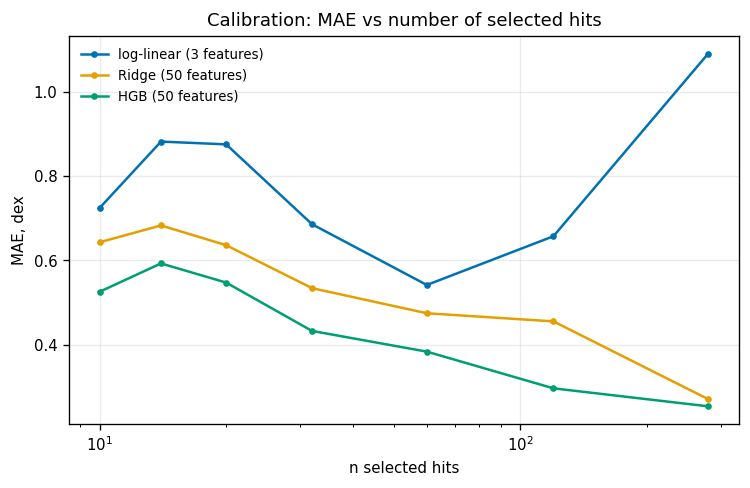

,model,class,n,mae,bias,within_factor_2
2,loglinear,nuatm,4650.000000,0.4862,-0.1935,0.334
3,loglinear,nue2,15350.000000,0.8443,+0.2537,0.223
6,ridge,nuatm,4650.000000,0.4975,-0.0663,0.383
7,ridge,nue2,15350.000000,0.6535,+0.1780,0.313
10,hgb,nuatm,4650.000000,0.4105,-0.1063,0.449
11,hgb,nue2,15350.000000,0.5449,+0.1122,0.390


In [7]:
nh_df = pd.read_parquet(RUN / "metrics_by_n_hits.parquet")
nh_df = nh_df[(nh_df.split == "cal") & (nh_df.model.isin(main_models))].copy()
nh_df["center"] = 0.5 * (nh_df.bin_lo + nh_df.bin_hi)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for model in main_models:
    d = nh_df[nh_df.model == model].sort_values("center")
    ax.plot(d.center, d.mae, marker="o", ms=3, lw=1.5,
            color=colors[model], label=model_labels[model])
ax.set_xscale("log")
ax.set_xlabel("n selected hits")
ax.set_ylabel("MAE, dex")
ax.set_title("Calibration: MAE vs number of selected hits")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8)
plt.show()

class_df = pd.read_parquet(RUN / "metrics_by_class.parquet")
class_df = class_df[(class_df.split == "cal") & (class_df.model.isin(main_models))]
class_df["class"] = class_df.particle_type.map({1: "nuatm", 2: "nue2"})
display(class_df[["model", "class", "n", "mae", "bias", "within_factor_2"]]
        .style.format({"mae": "{:.4f}", "bias": "{:+.4f}", "within_factor_2": "{:.3f}"}))

## 5. Разброс по партам

События одного MC-парта коррелированы. Глобальный MAE может скрывать
систематику отдельного парта, поэтому ниже — распределение per-part MAE на
калибровочной выборке и зависимость MAE от числа событий в парте.

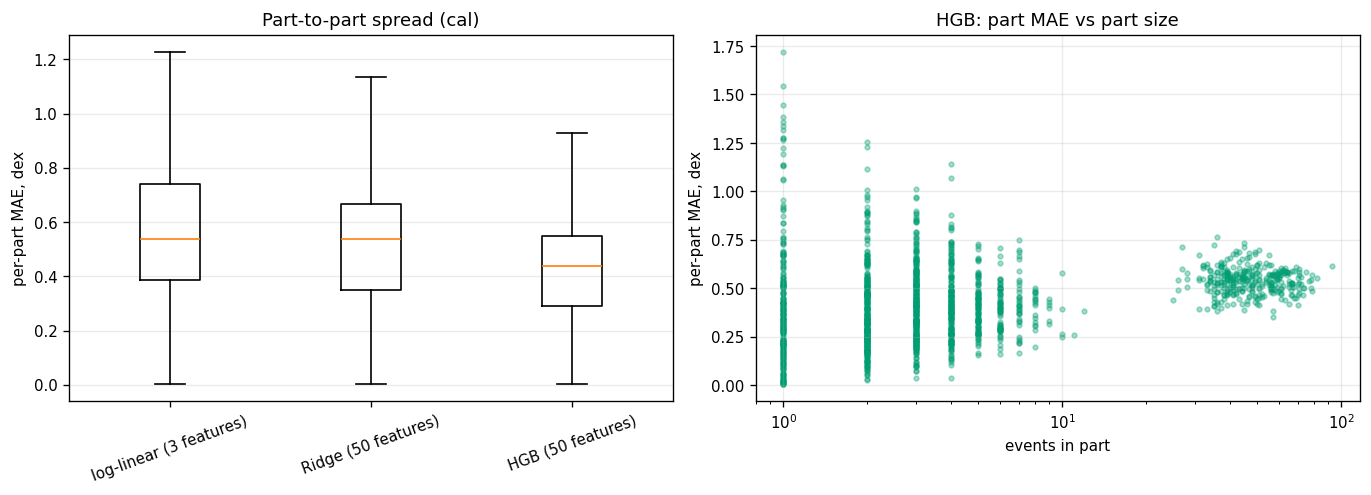

per-part MAE summary (cal):


,count,mean,std,50%
model,,,,
hgb,1574.0,0.437607,0.203755,0.437485
loglinear,1574.0,0.557381,0.240476,0.536216
ridge,1574.0,0.525436,0.240929,0.539216


In [8]:
part = pd.read_parquet(RUN / "part_metrics.parquet")
part = part[(part.split == "cal") & (part.model.isin(main_models))]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
data = [part[part.model == m].mae.dropna().to_numpy() for m in main_models]
axes[0].boxplot(data, tick_labels=[model_labels[m] for m in main_models],
                showfliers=False)
axes[0].set_ylabel("per-part MAE, dex")
axes[0].set_title("Part-to-part spread (cal)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)
d = part[part.model == "hgb"]
axes[1].scatter(d.n, d.mae, s=8, alpha=0.35, color=colors["hgb"])
axes[1].set_xscale("log")
axes[1].set_xlabel("events in part")
axes[1].set_ylabel("per-part MAE, dex")
axes[1].set_title("HGB: part MAE vs part size")
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

print("per-part MAE summary (cal):")
display(part.groupby("model")["mae"].describe()[["count", "mean", "std", "50%"]])

## 6. Абляции признаков

Одна и та же HGB-конфигурация на разных группах признаков. Это отвечает на
вопрос, что даёт геометрия и что добавляет время.

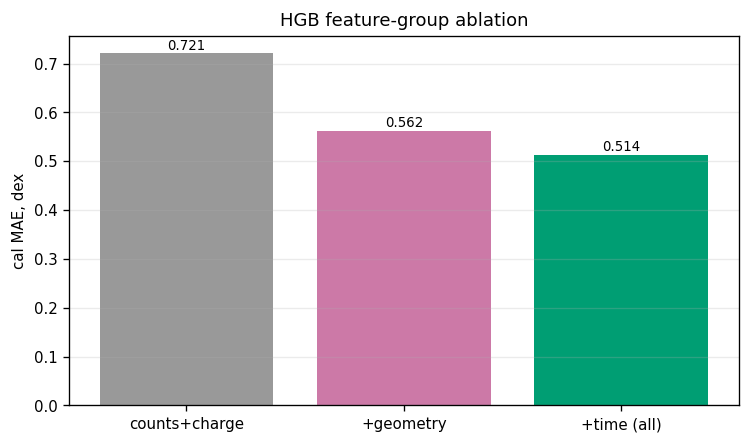

In [9]:
abl_names = ["hgb_counts_charge", "hgb_counts_charge_geometry", "hgb"]
abl_labels = ["counts+charge", "+geometry", "+time (all)"]
abl_mae = [metrics["global"]["cal"][n]["mae"] for n in abl_names]
abl_w = [metrics["global"]["cal"][n]["w_mae"] for n in abl_names]
fig, ax = plt.subplots(figsize=(7.2, 4.0))
xx = np.arange(len(abl_names))
ax.bar(xx, abl_mae, color=["#999999", "#CC79A7", "#009E73"])
ax.set_xticks(xx, abl_labels)
ax.set_ylabel("cal MAE, dex")
ax.set_title("HGB feature-group ablation")
for i, v in enumerate(abl_mae):
    ax.text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=8)
ax.grid(axis="y", alpha=0.25)
plt.show()

## 7. Важность признаков

Permutation importance HGB на val-select: насколько падает MAE при перемешивании
одного признака. Это не причинный эффект, а чувствительность модели.

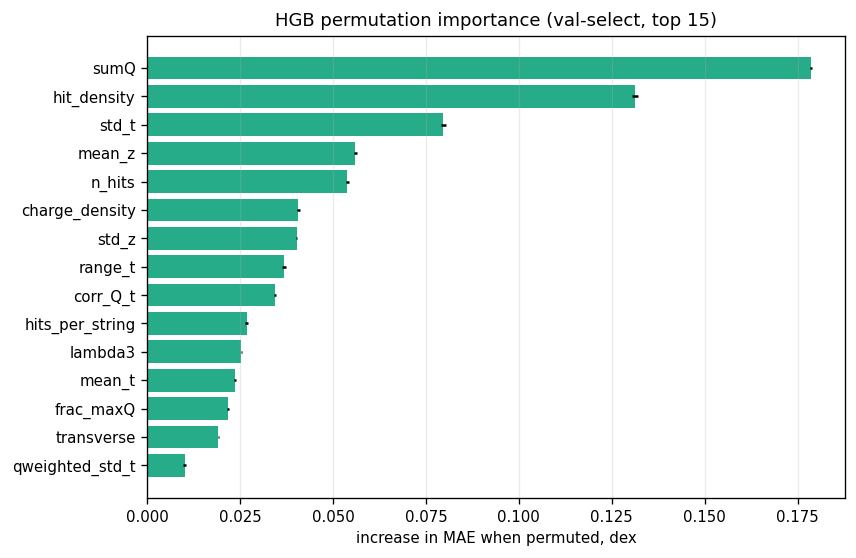

In [10]:
imp = pd.read_parquet(RUN / "feature_importance.parquet").sort_values(
    "importance_mean", ascending=False
).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5.0))
ax.barh(imp.feature, imp.importance_mean,
        xerr=imp.importance_std, color="#009E73", alpha=0.85)
ax.set_xlabel("increase in MAE when permuted, dex")
ax.set_title("HGB permutation importance (val-select, top 15)")
ax.grid(axis="x", alpha=0.25)
plt.show()

## 8. Итог по non-neural моделям

На калибровочной выборке (20k событий, не использованных для выбора модели):

- HGB: MAE ≈ 0.514 dex, bias +0.061;
- Ridge: MAE ≈ 0.617 dex, bias +0.121;
- log-linear на трёх признаках: MAE ≈ 0.761 dex, bias +0.150.

Геометрия даёт большой вклад: HGB на counts+charge — MAE ≈ 0.721, после
добавления геометрии — ≈ 0.563, после времени — ≈ 0.514. Время и геометрия
несут реальную информацию, хотя последовательностная модель не используется.

Ограничения:

- это **не финальный part-level test**: `calibration` — event-level holdout
  внутри train-партов; новых test-партов в этом датасете нет;
- `train`-метрики — in-sample и приведены только для контроля переобучения;
- `Q_clip=100` — общий вход с нейросетью, но raw-Q ablation здесь не строится;
- один split/seed; part-level bootstrap ещё не является полноценной оценкой
  неопределённости между прогонами;
- MAE зависит от `E_true`; смотреть только на глобальное число нельзя.

## 9. Что дальше

1. Test-признаки и предсказания non-neural HGB на новых партах уже построены;
   последний блок ноутбука сравнивает их с рабочей моделью AC-G на 418 153 test-событиях.
2. При смене нейросетевого чекпоинта меняется только путь в `NN_PREDICTIONS`.
3. Для следующего шага — part-level bootstrap ΔMAE и сравнение нескольких
   seed/split, прежде чем делать вывод о преимуществе нейросети.


## 10. Сравнение с нейросетью — последний блок

В этом прогоне заполнено сравнение с **AC-G**: рабочая модель с DANN,
совместно обученными mean- и Gaussian NLL-головой для sigma.
Сравнение идёт по mean-предсказанию `pred_log10e` на тех же 418 153
test-событиях; baseline — HGB на handcrafted-признаках, обученный на
train-партах.

Путь к чекпоинту вынесен в `NN_PREDICTIONS`; при смене чекпоинта меняется
только эта строка. Binning по `E_pred` здесь не строится — сравнение идёт по
`E_true`.


,label,n,MAE_baseline,MAE_nn,delta_MAE(nn-base),bias_baseline,bias_nn
0,Working model (Gaussian + DANN),418153,0.5212,0.4748,-0.0464,+0.0912,+0.1564


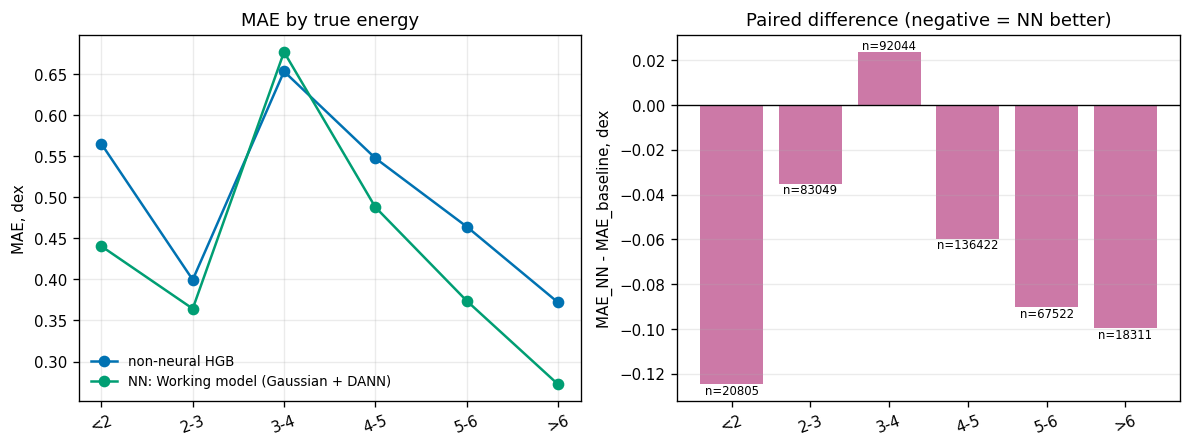

In [11]:
BASELINE_TEST_DB = ROOT / (
    "inference/track_energy_reconstruction/preds/"
    "261026_1725_non_neural_energy_baseline_partsplit_s42@hgb/test.duckdb"
)
NN_PREDICTIONS = {
    "Working model (Gaussian + DANN)": ROOT / (
        "inference/track_energy_reconstruction/preds/"
        "261027_0935_mu_energy_AC-G_partsplit_scratch_s42@best_model/"
        "mc_merged_h8s3_thr0p8.duckdb"
    ),
}
SPLIT_NAME = "test"

if not NN_PREDICTIONS or BASELINE_TEST_DB is None:
    print("NN comparison skipped: fill NN_PREDICTIONS and BASELINE_TEST_DB.")
else:
    def load_pred(path, split=SPLIT_NAME):
        path = Path(path)
        if path.suffix == ".duckdb":
            c = duckdb.connect(str(path), read_only=True)
            d = c.execute("SELECT * FROM predictions").df()
            c.close()
        else:
            d = pd.read_parquet(path)
        if "split" in d.columns:
            d = d[d.split == split].copy()
        return d

    base = load_pred(BASELINE_TEST_DB)
    if "model" in base.columns:
        base = base[base.model == "hgb"].copy()

    rows = []
    merged_by_label = {}
    for label, path in NN_PREDICTIONS.items():
        nn = load_pred(path)
        merged = base.merge(
            nn[["event_fk", "pred_log10e"]],
            on="event_fk", suffixes=("_base", "_nn"),
        )
        if merged.empty:
            print(f"{label}: no event_fk match")
            continue
        merged = merged.rename(columns={"pred_log10e_base": "pred_base",
                                        "pred_log10e_nn": "pred_nn"})
        merged["err_base"] = merged.true_log10e - merged.pred_base
        merged["err_nn"] = merged.true_log10e - merged.pred_nn
        merged_by_label[label] = merged
        rows.append({
            "label": label,
            "n": len(merged),
            "MAE_baseline": float(merged.err_base.abs().mean()),
            "MAE_nn": float(merged.err_nn.abs().mean()),
            "delta_MAE(nn-base)": float(
                merged.err_nn.abs().mean() - merged.err_base.abs().mean()
            ),
            "bias_baseline": float(merged.err_base.mean()),
            "bias_nn": float(merged.err_nn.mean()),
        })

    if rows:
        display(pd.DataFrame(rows).style.format({
            "MAE_baseline": "{:.4f}", "MAE_nn": "{:.4f}",
            "delta_MAE(nn-base)": "{:+.4f}",
            "bias_baseline": "{:+.4f}", "bias_nn": "{:+.4f}",
        }))

        # Per true-energy-bin comparison, one panel per metric.
        bins = [-1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0]
        labels = ["<2", "2-3", "3-4", "4-5", "5-6", ">6"]
        for label, merged in merged_by_label.items():
            merged["ebin"] = pd.cut(
                merged.true_log10e, bins=bins, labels=labels, right=False
            )
            by_bin = merged.groupby("ebin", observed=True).agg(
                n=("event_fk", "size"),
                mae_base=("err_base", lambda x: x.abs().mean()),
                mae_nn=("err_nn", lambda x: x.abs().mean()),
            ).reset_index()
            by_bin["delta"] = by_bin.mae_nn - by_bin.mae_base
            fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
            x = np.arange(len(by_bin))
            axes[0].plot(x, by_bin.mae_base, marker="o", color="#0072B2",
                         label="non-neural HGB")
            axes[0].plot(x, by_bin.mae_nn, marker="o", color="#009E73",
                         label="NN: " + label)
            axes[0].set_xticks(x, by_bin.ebin.astype(str), rotation=20)
            axes[0].set_ylabel("MAE, dex")
            axes[0].set_title("MAE by true energy")
            axes[0].legend(frameon=False, fontsize=8)
            axes[0].grid(alpha=0.25)
            axes[1].bar(x, by_bin.delta, color="#CC79A7")
            axes[1].axhline(0, color="black", lw=0.8)
            axes[1].set_xticks(x, by_bin.ebin.astype(str), rotation=20)
            axes[1].set_ylabel("MAE_NN - MAE_baseline, dex")
            axes[1].set_title("Paired difference (negative = NN better)")
            axes[1].grid(axis="y", alpha=0.25)
            for i, row in by_bin.reset_index(drop=True).iterrows():
                axes[1].text(i, row.delta, f"n={int(row.n)}", ha="center",
                             va="bottom" if row.delta >= 0 else "top", fontsize=7)
            fig.tight_layout()
            plt.show()
